# Exploratory Data Analysis

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [2]:
from pathlib import Path
import pandas as pd

path = Path.cwd()

file_path = path.parent / "Data" / "ai4i2020.csv"

data = pd.read_csv(file_path)

df=data.copy()
df

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0


In [3]:
df.shape

(10000, 14)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

Column short-from Meanings : 

- TWF	=Tool Wear Failure	
- HDF	=Heat Dissipation 	
- PWF	=Power Failure	
- OSF	=Overstrain Failure	
- RNF	=Random Failure


> so according to our dataset  we have 6 target columns in our data including machine failure column. 

- But we will only use machine failure as our main target column for this primary EDA task 

In [5]:
# we will drop it temporarily 

df=df.drop(columns=['TWF','HDF','PWF','OSF','RNF'], axis=1)


In [6]:
df

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,1,M14860,M,298.1,308.6,1551,42.8,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0
...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0


In [7]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000


In [8]:
df.tail()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0


In [9]:
df['UDI']

0           1
1           2
2           3
3           4
4           5
        ...  
9995     9996
9996     9997
9997     9998
9998     9999
9999    10000
Name: UDI, Length: 10000, dtype: int64

In [10]:
df

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,1,M14860,M,298.1,308.6,1551,42.8,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0
...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0


In [11]:
df['UDI']

0           1
1           2
2           3
3           4
4           5
        ...  
9995     9996
9996     9997
9997     9998
9998     9999
9999    10000
Name: UDI, Length: 10000, dtype: int64

In [12]:
# UDI of no use too
df=df.drop('UDI',axis=1)

In [13]:
df

,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,M14860,M,298.1,308.6,1551,42.8,0,0
1,L47181,L,298.2,308.7,1408,46.3,3,0
2,L47182,L,298.1,308.5,1498,49.4,5,0
3,L47183,L,298.2,308.6,1433,39.5,7,0
4,L47184,L,298.2,308.7,1408,40.0,9,0
...,...,...,...,...,...,...,...,...
9995,M24855,M,298.8,308.4,1604,29.5,14,0
9996,H39410,H,298.9,308.4,1632,31.8,17,0
9997,M24857,M,299.0,308.6,1645,33.4,22,0
9998,H39412,H,299.0,308.7,1408,48.5,25,0


In [14]:
df['Machine failure'].unique()

array([0, 1])

In [15]:
df=df.rename(columns={'Machine failure':'MachineFailure'})
df

,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],MachineFailure
0,M14860,M,298.1,308.6,1551,42.8,0,0
1,L47181,L,298.2,308.7,1408,46.3,3,0
2,L47182,L,298.1,308.5,1498,49.4,5,0
3,L47183,L,298.2,308.6,1433,39.5,7,0
4,L47184,L,298.2,308.7,1408,40.0,9,0
...,...,...,...,...,...,...,...,...
9995,M24855,M,298.8,308.4,1604,29.5,14,0
9996,H39410,H,298.9,308.4,1632,31.8,17,0
9997,M24857,M,299.0,308.6,1645,33.4,22,0
9998,H39412,H,299.0,308.7,1408,48.5,25,0


In [16]:
df['Type'].unique()

array(['M', 'L', 'H'], dtype=object)

In [17]:
df['Product ID'].nunique()

10000

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
df.isna().sum()

Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
MachineFailure             0
dtype: int64

In [20]:
df.isnull().sum()

Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
MachineFailure             0
dtype: int64

In [21]:
df.head(10)

,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],MachineFailure
0,M14860,M,298.1,308.6,1551,42.8,0,0
1,L47181,L,298.2,308.7,1408,46.3,3,0
2,L47182,L,298.1,308.5,1498,49.4,5,0
3,L47183,L,298.2,308.6,1433,39.5,7,0
4,L47184,L,298.2,308.7,1408,40.0,9,0
5,M14865,M,298.1,308.6,1425,41.9,11,0
6,L47186,L,298.1,308.6,1558,42.4,14,0
7,L47187,L,298.1,308.6,1527,40.2,16,0
8,M14868,M,298.3,308.7,1667,28.6,18,0
9,M14869,M,298.5,309.0,1741,28.0,21,0


In [22]:
correlation=df.corr(numeric_only=True)
correlation

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],MachineFailure
Air temperature [K],1.000000,0.876107,0.022670,-0.013778,0.013853,0.082556
Process temperature [K],0.876107,1.000000,0.019277,-0.014061,0.013488,0.035946
Rotational speed [rpm],0.022670,0.019277,1.000000,-0.875027,0.000223,-0.044188
Torque [Nm],-0.013778,-0.014061,-0.875027,1.000000,-0.003093,0.191321
Tool wear [min],0.013853,0.013488,0.000223,-0.003093,1.000000,0.105448
MachineFailure,0.082556,0.035946,-0.044188,0.191321,0.105448,1.000000


In [23]:
# corrwith() calculats corr with col with one spf one 
spf_corr=df.corrwith(df['MachineFailure'], numeric_only=True,method='pearson').sort_values(ascending=False)
spf_corr

# pearson only measure linear reln

MachineFailure             1.000000
Torque [Nm]                0.191321
Tool wear [min]            0.105448
Air temperature [K]        0.082556
Process temperature [K]    0.035946
Rotational speed [rpm]    -0.044188
dtype: float64

In [24]:
df.corr(method='spearman', numeric_only=True)['MachineFailure'].sort_values(ascending=False)
# spearman is capable of measuring mono tonic rln as well 

MachineFailure             1.000000
Torque [Nm]                0.169413
Tool wear [min]            0.101630
Air temperature [K]        0.083223
Process temperature [K]    0.039946
Rotational speed [rpm]    -0.167188
Name: MachineFailure, dtype: float64

In [25]:
df.head()

,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],MachineFailure
0,M14860,M,298.1,308.6,1551,42.8,0,0
1,L47181,L,298.2,308.7,1408,46.3,3,0
2,L47182,L,298.1,308.5,1498,49.4,5,0
3,L47183,L,298.2,308.6,1433,39.5,7,0
4,L47184,L,298.2,308.7,1408,40.0,9,0


In [26]:
df.skew(numeric_only=True)

Air temperature [K]        0.114274
Process temperature [K]    0.015027
Rotational speed [rpm]     1.993171
Torque [Nm]               -0.009517
Tool wear [min]            0.027292
MachineFailure             5.151852
dtype: float64

- Skewness value	Interpretation
- 0	Perfectly   -------  symmetrical
- -0.5 to +0.5	------  Approximately symmetric
- -1 to -0.5	 ------  Moderately negatively skewed
- +0.5 to +1	------  Moderately positively skewed
- Below -1	    ----- Highly negatively skewed
- Above +1	   ------  Highly positively skewed

<Axes: ylabel='Density'>

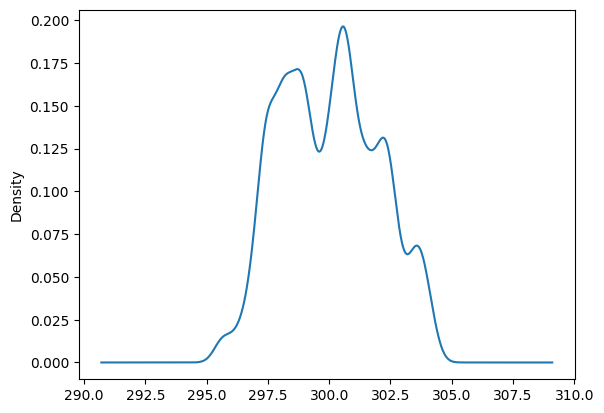

In [27]:
df['Air temperature [K]'].plot(kind='kde')

Text(0.5, 1.0, 'MachineFailure skewness')

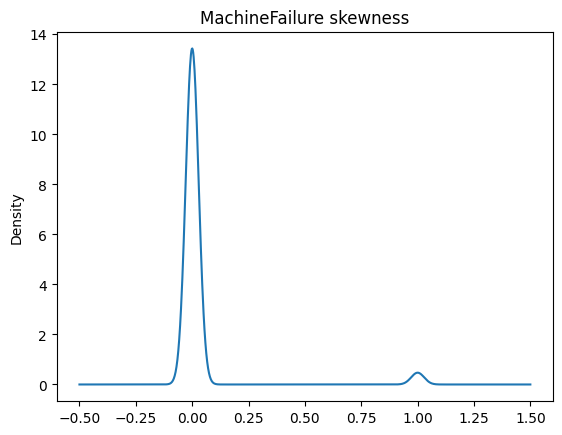

In [28]:
df['MachineFailure'].plot(kind='kde')
plt.title('MachineFailure skewness')

In [29]:
df['MachineFailure'].value_counts()

MachineFailure
0    9661
1     339
Name: count, dtype: int64

> okay, so there is imbalance in label ... So this imbalance cause bias to model , as nonfailure is way more than  failure model will learn/have acess to non-failure pattern and will give less priority to the failure .

- The problem is that the model can become biased towards the majority class (non-failure).

In [30]:
df.head(8)

,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],MachineFailure
0,M14860,M,298.1,308.6,1551,42.8,0,0
1,L47181,L,298.2,308.7,1408,46.3,3,0
2,L47182,L,298.1,308.5,1498,49.4,5,0
3,L47183,L,298.2,308.6,1433,39.5,7,0
4,L47184,L,298.2,308.7,1408,40.0,9,0
5,M14865,M,298.1,308.6,1425,41.9,11,0
6,L47186,L,298.1,308.6,1558,42.4,14,0
7,L47187,L,298.1,308.6,1527,40.2,16,0


In [31]:
df['Type'].value_counts()

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

### Univariate Analysis

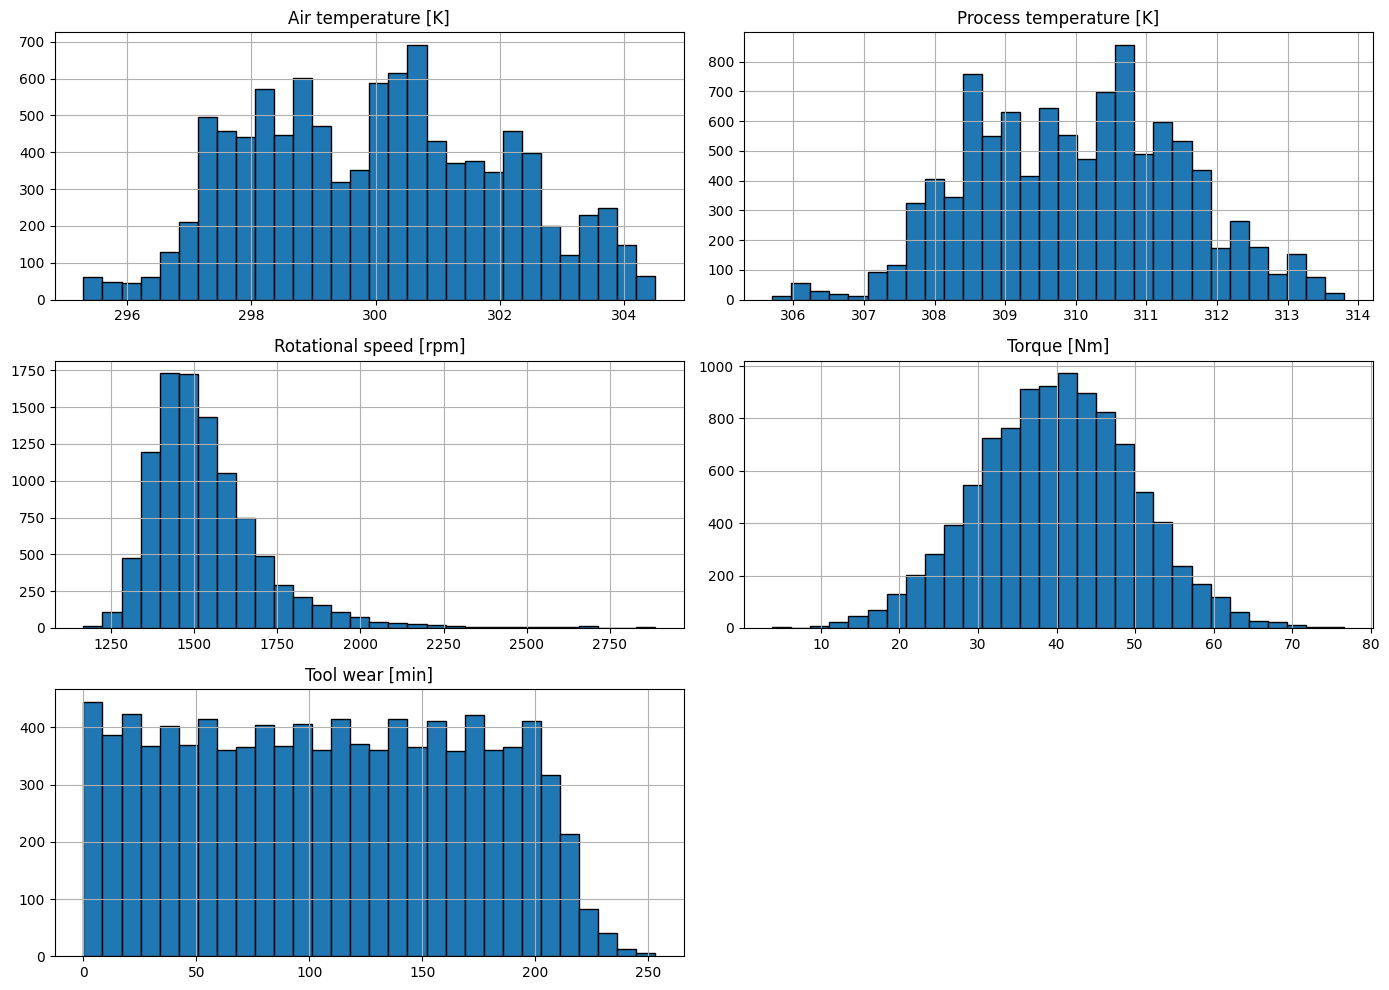

In [32]:
numerical_col=[
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

df[numerical_col].hist(bins=30,figsize=(14,10),edgecolor='black') # 20-30 BINS GIVE more detaileed info about data 

plt.tight_layout()
plt.show()

In [33]:
df['Rotational speed [rpm]'].skew()

np.float64(1.993171004713752)

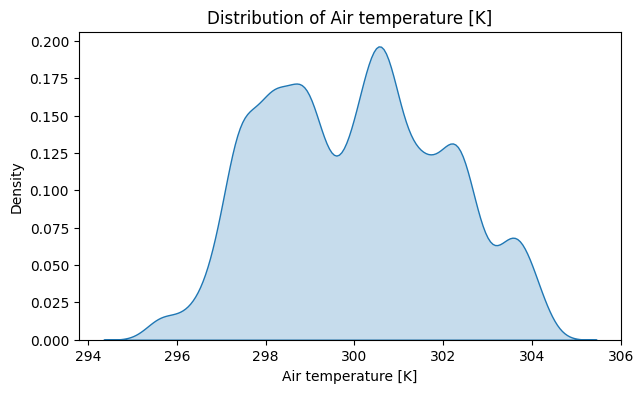

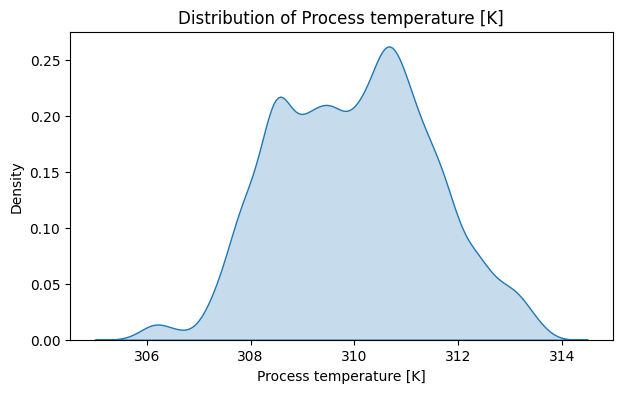

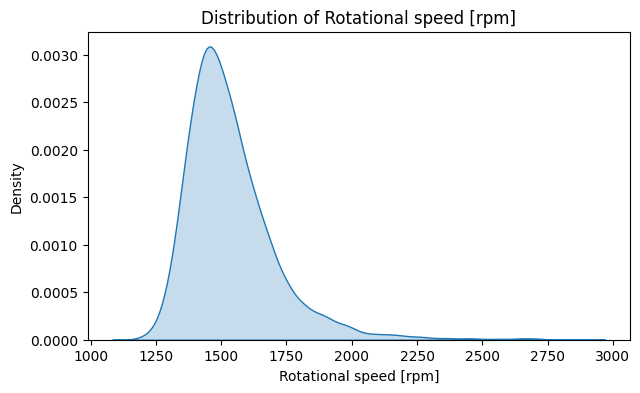

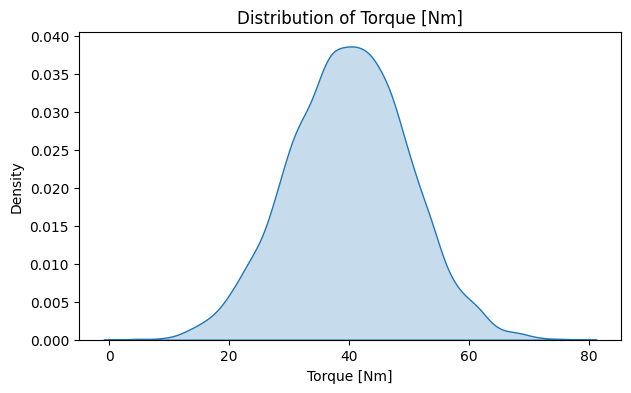

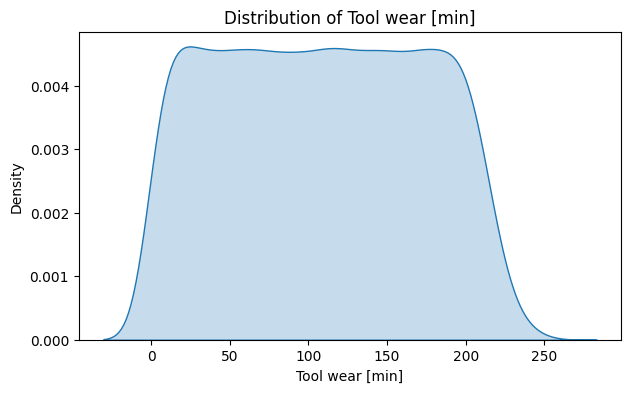

In [34]:
for col in numerical_col:
    plt.figure(figsize=(7, 4))
    sns.kdeplot(data=df, x=col, fill=True)
    plt.title(f'Distribution of {col}')
    plt.show()

so from above graphs and plot we can confirm :

1. The distribution shows fluctuations and multiple peaks, suggesting observations are concentrated around several temperature ranges rather than one clear central peak.
2. Process temperature has several visible peaks data not approx uniform 
3. rotational speed is right skewed . 
4. Torque follows normal distribution 
5. tool wear has multiple peaks indicating that multiple values are higher than what normal are . 

In [35]:
df.describe()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],MachineFailure
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900
std,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981
min,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000


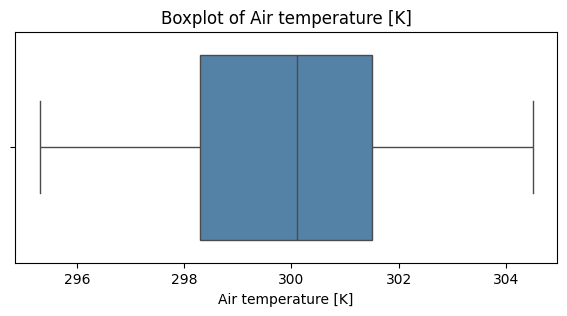

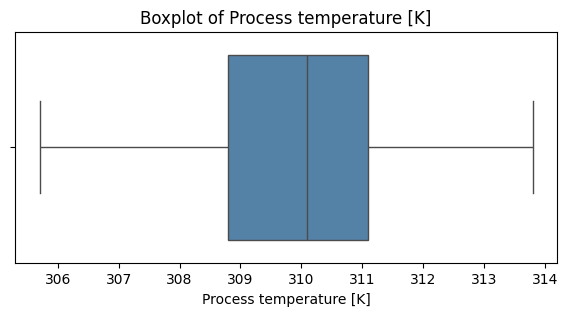

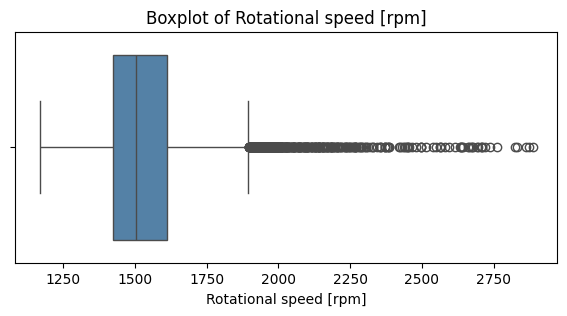

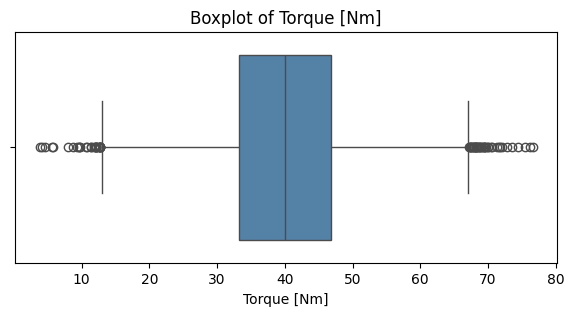

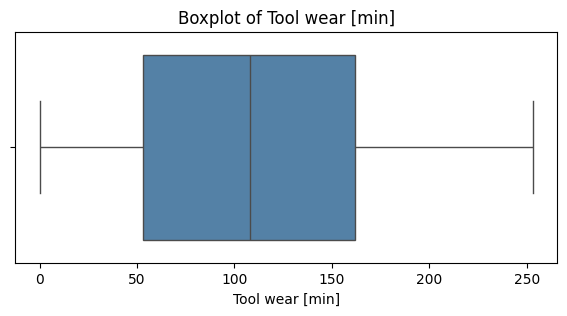

In [36]:
for col in numerical_col:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df[col],color='steelblue' )
    plt.title(f'Boxplot of {col}')
    plt.show()

Rotational speed and torque have significant number of outliers . whereas other remaining columns stay within the range. 

In [37]:
# lets see the outlier ranges too
for col in numerical_col:
    iqr=df[col].quantile(0.75)-df[col].quantile(0.25)
    print(f"{col} \n")
    print("IQR:",iqr)
    lower_bound=df[col].quantile(0.25)-1.5* iqr
    upper_bound=df[col].quantile(0.75)+1.5* iqr
    count = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    print('Lower Boundary:',lower_bound)
    print('Upper Boundary:',upper_bound)
    print('No of outlier:',count)
    
    print()



Air temperature [K] 

IQR: 3.1999999999999886
Lower Boundary: 293.5
Upper Boundary: 306.29999999999995
No of outlier: 0

Process temperature [K] 

IQR: 2.3000000000000114
Lower Boundary: 305.35
Upper Boundary: 314.55000000000007
No of outlier: 0

Rotational speed [rpm] 

IQR: 189.0
Lower Boundary: 1139.5
Upper Boundary: 1895.5
No of outlier: 418

Torque [Nm] 

IQR: 13.599999999999994
Lower Boundary: 12.800000000000011
Upper Boundary: 67.19999999999999
No of outlier: 69

Tool wear [min] 

IQR: 109.0
Lower Boundary: -110.5
Upper Boundary: 325.5
No of outlier: 0



In [38]:
# we wont immediately remove outlier as the machine failure might also be associated with extreme speed or torque as well.

### Bivariate Analysis

In [39]:
df.dtypes

Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
MachineFailure               int64
dtype: object

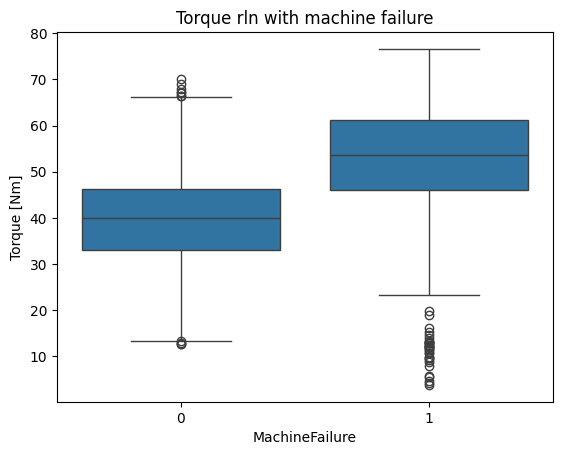

In [40]:
# lets see the rln of rotational speed & torque with machine failure 
sns.boxplot(data=df, x="MachineFailure", y="Torque [Nm]") # x & y are cols 
plt.title('Torque rln with machine failure')
plt.show()

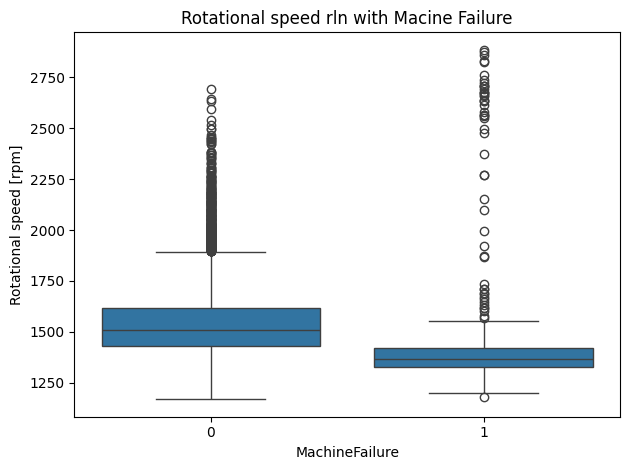

In [41]:
# rotational speed relation with machinefailure 

# rotational speed has 418 outliers 
sns.boxplot(data=df, x='MachineFailure',y='Rotational speed [rpm]')
plt.title("Rotational speed rln with Macine Failure")

plt.tight_layout()
plt.show()

from the box plot where we saw relation of both the col with outlier with machine failure , 

- most of the outlier were for machine failure than non-failure. 
- so the outlier can be the casue of failure for machine i.e due to high speed or low torque .  so we will keep the outliers for now and wont remove till we are very sure.

In [42]:
df.head()

,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],MachineFailure
0,M14860,M,298.1,308.6,1551,42.8,0,0
1,L47181,L,298.2,308.7,1408,46.3,3,0
2,L47182,L,298.1,308.5,1498,49.4,5,0
3,L47183,L,298.2,308.6,1433,39.5,7,0
4,L47184,L,298.2,308.7,1408,40.0,9,0


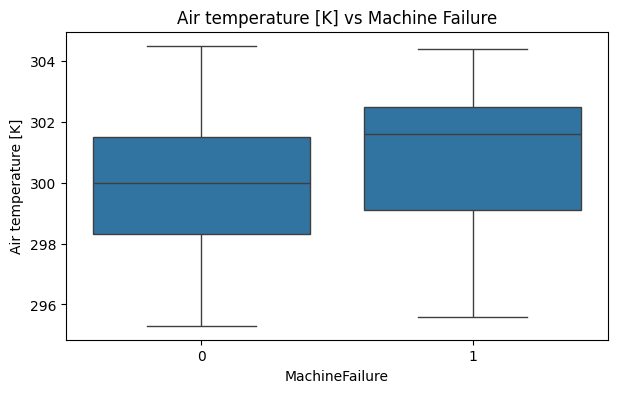

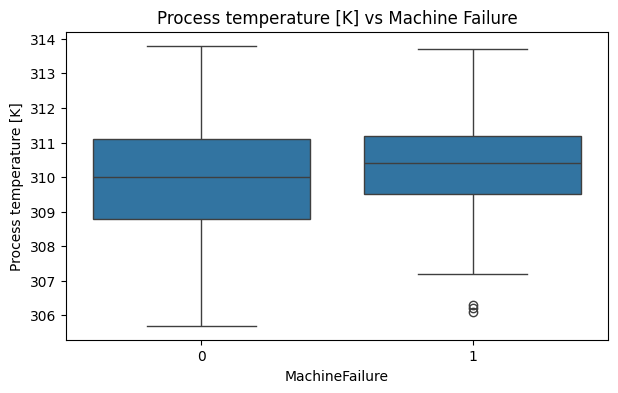

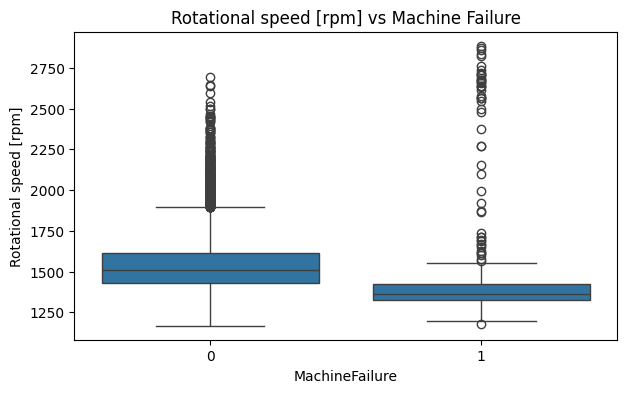

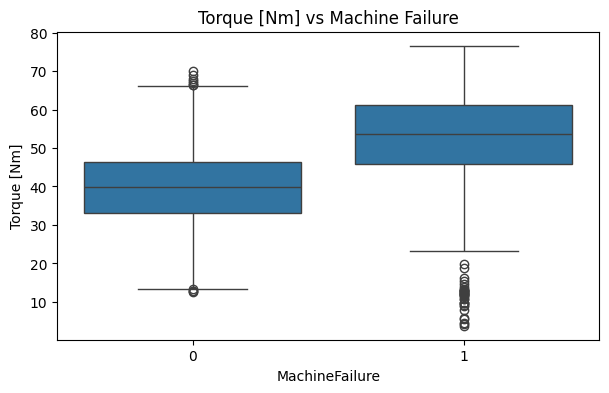

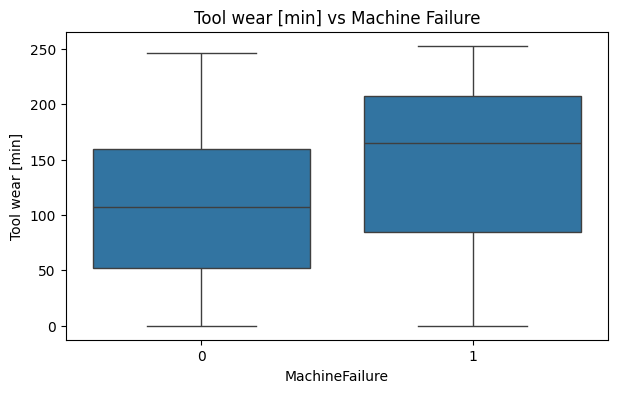

In [64]:
for col in numerical_col:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x='MachineFailure', y=col)
    plt.title(f'{col} vs Machine Failure')
    plt.show()

In [43]:
# which type of machine is more prone to machine failure ? 

prone=df.groupby('Type')['MachineFailure'].mean()
prone

Type
H    0.020937
L    0.039167
M    0.027694
Name: MachineFailure, dtype: float64

Text(0.5, 1.0, 'Average MachineFailure based on type of machine')

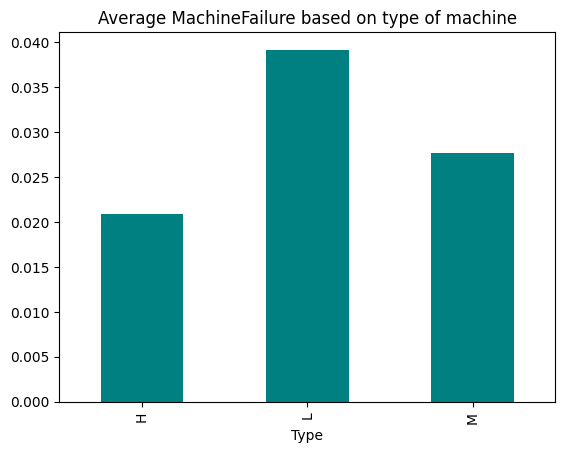

In [44]:
prone.plot(kind='bar',color='Teal')
plt.title("Average MachineFailure based on type of machine")

Lower quality machine are more prone to MachineFailure

In [45]:
pd.crosstab(df['Type'],df['MachineFailure'])

MachineFailure,0,1
Type,,
H,982,21
L,5765,235
M,2914,83


In [46]:
pd.crosstab(df['Type'],df['MachineFailure'],normalize='index')*100

MachineFailure,0,1
Type,,
H,97.906281,2.093719
L,96.083333,3.916667
M,97.230564,2.769436


so yes compared to other quality , lower quality machine have 235 failures or nearly 4% failure rate compared to other type where 
- High quality has the least rate of failure : 21 or 2.09%
- Medium quality 83 failure or 2.7% 

In [47]:
df.head()

,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],MachineFailure
0,M14860,M,298.1,308.6,1551,42.8,0,0
1,L47181,L,298.2,308.7,1408,46.3,3,0
2,L47182,L,298.1,308.5,1498,49.4,5,0
3,L47183,L,298.2,308.6,1433,39.5,7,0
4,L47184,L,298.2,308.7,1408,40.0,9,0


In [48]:
# hows  air temerature's behaviour with machine failure ? 

# first group the temperature in groups 

group_temp=pd.cut(df['Air temperature [K]'],bins=4, labels=['Low','Mild','High','extreme'])

# then we will see which interval leads to highest machine failure(1)
result=df.groupby(group_temp)['MachineFailure'].mean().sort_values(ascending=False)
result


/var/folders/7r/6c5w6tr551b0q1_3l2f2q4ph0000gn/T/ipykernel_1599/1931814431.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  result=df.groupby(group_temp)['MachineFailure'].mean().sort_values(ascending=False)


Air temperature [K]
extreme    0.069969
High       0.033035
Mild       0.022814
Low        0.021521
Name: MachineFailure, dtype: float64

<Axes: ylabel='Air temperature [K]'>

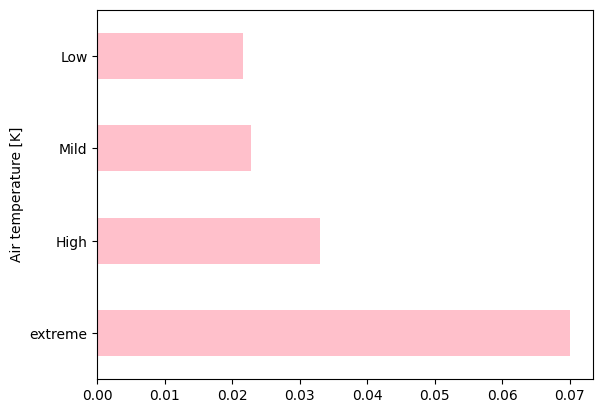

In [49]:
result.plot(kind='barh',color='pink')

so in avergae extreme air temperature leads to machine failure.. 

In [50]:
df.head()

,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],MachineFailure
0,M14860,M,298.1,308.6,1551,42.8,0,0
1,L47181,L,298.2,308.7,1408,46.3,3,0
2,L47182,L,298.1,308.5,1498,49.4,5,0
3,L47183,L,298.2,308.6,1433,39.5,7,0
4,L47184,L,298.2,308.7,1408,40.0,9,0


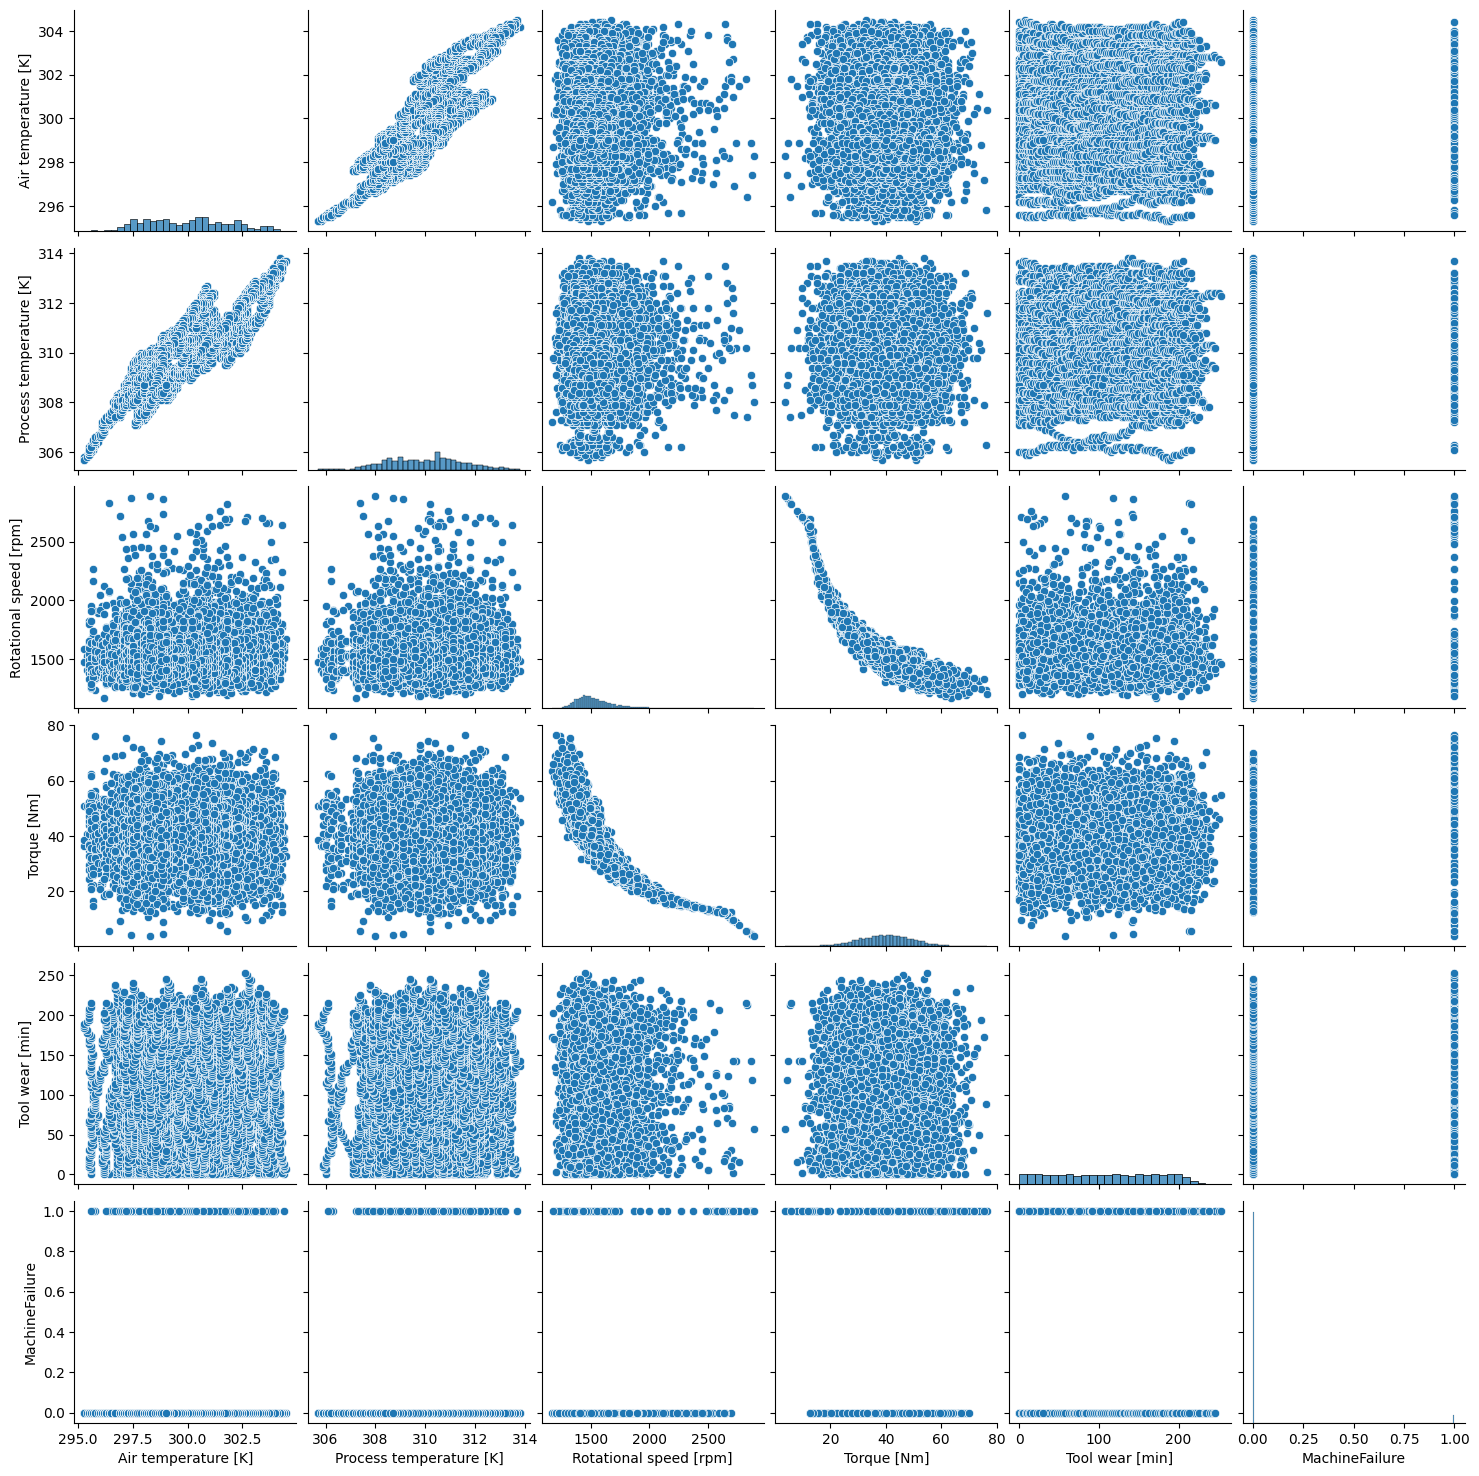

In [52]:
sns.pairplot(df)

In [59]:
# we had earlier analyzed that the target binary categorical column has imbalanced classes 
df['MachineFailure'].value_counts()

MachineFailure
0    9661
1     339
Name: count, dtype: int64

Due to this imbalanced class , the model we will train will be more focused toward te class with abduance of value and pattern and dosen't give much importance to the class whose information is less avalilabe to the model . 

so this create a bias in the model . Even if the model achives high accuracy that is of usually of no use . 

In [63]:
# so we will handle this imbalance class problem 


So to solve imbalanced data problem, we have few approaches that we can use 

1. undersampling: randomly sample majority class and take out the data so that it becomes equal to minority. 
2. Oversampling: duplicate the minority class with majoirty calss till it balances but might cause overfitting. 
3. SMOTE: same as oversampling , but instead of duplicating we will interpolate ,fill the minorty class , but is only limited to the Numerical col. 
4. Ensemble method - use balanced random forest 
3. class weight 

In [ ]:
# will be handled in next notebook - models.ipynb

In [67]:
from pathlib import Path

output_path = Path.cwd().parent / "Data" / "cleaned_data.csv"

df.to_csv(output_path, index=False)

In [66]:
df

,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],MachineFailure
0,M14860,M,298.1,308.6,1551,42.8,0,0
1,L47181,L,298.2,308.7,1408,46.3,3,0
2,L47182,L,298.1,308.5,1498,49.4,5,0
3,L47183,L,298.2,308.6,1433,39.5,7,0
4,L47184,L,298.2,308.7,1408,40.0,9,0
...,...,...,...,...,...,...,...,...
9995,M24855,M,298.8,308.4,1604,29.5,14,0
9996,H39410,H,298.9,308.4,1632,31.8,17,0
9997,M24857,M,299.0,308.6,1645,33.4,22,0
9998,H39412,H,299.0,308.7,1408,48.5,25,0


In [68]:
# Next -> models.ipynb
